# 07. 중간발표 EDA 보강 — 원본 EMS 데이터 분석 (모델 결과 아님)
원본 구급 기록을 정제·전처리한 뒤, **데이터 분석만으로** 프로젝트 질문에 답할 수 있는지 본다. 모델은 쓰지 않는다. 인과가 아니라 **연관**이다. 2025 시험 구간은 쓰지 않는다.

- **P1~P3 정제·전처리**: 원본(서울 2024)에서 규칙별 제외, 결측률, 거리 이상치
- **Q1 거리·시간대·관외출동**(교수님 피드백: 관외출동), **Q2 구별 관외출동**, **Q3 강수(거리 통제)**, **Q4 구×시간대·구×연도**
입력: `work/seoul_2024_raw.csv`, `data/splits/`, `work/base_v1/`(구급 개인 기록 계열, 커밋 금지).

In [1]:
import os, shutil, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.weather.asos import attach_rain, load_config

warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False; plt.rcParams["figure.dpi"] = 110
OUT = Path("work/figures/07"); OUT_T = OUT
TBL = Path("work/tables/07"); TBL_T = TBL
for p in (OUT, TBL): p.mkdir(parents=True, exist_ok=True)
NA = [chr(92) + "N", ""]
BANDS = ["심야(0-5)", "출근(6-9)", "낮(10-16)", "퇴근(17-20)", "야간(21-23)"]
DLAB = ["≤1km", "1-2", "2-3", "3-4", "4-6", ">6km"]

def heat(ax, tab, n, title, fmt="{:.0%}", vmin=.3, vmax=.7, minn=200):
    t = tab.where(n >= minn)
    im = ax.imshow(t.to_numpy(float), cmap="RdYlBu_r", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns, fontsize=8)
    ax.set_yticks(range(t.shape[0])); ax.set_yticklabels(t.index, fontsize=8)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            if not np.isnan(t.iat[i, j]):
                ax.text(j, i, fmt.format(t.iat[i, j]) + " (" + str(int(n.iat[i, j])) + ")", ha="center", va="center", fontsize=6.5)
    ax.set_title(title)
    return im

## P1. 정제 규칙별 제외 건수 — 원본에서 직접 계산 (문서의 값 9,672 / 25,099 / 118 / 363과 일치)

In [2]:
raw = pd.read_csv("work/seoul_2024_raw.csv", dtype=str, na_values=NA, low_memory=False)
raw.columns = raw.columns.str.lower()

def ts(ymd, tm):
    return pd.to_datetime(ymd + tm.str.zfill(6), format="%Y%m%d%H%M%S", errors="coerce")

dclr = ts(raw.dclr_ymd, raw.dclr_tm); dspt = ts(raw.dspt_ymd, raw.dspt_tm)
arvl = ts(raw.grnds_arvl_ymd, raw.grnds_arvl_tm); cbk = ts(raw.cbk_ymd, raw.cbk_tm)
cancel = raw.trmn_se_nm.eq("취소")
miss = ~cancel & (dclr.isna() | arvl.isna())
ok = ~cancel & ~miss
resp = (arvl - dclr).dt.total_seconds() / 60
bad = ok & (resp <= 0); over = ok & ~bad & (resp > 180)
kept = ok & ~bad & ~over
steps = [("서울 2024 전체", len(raw)), ("취소", -int(cancel.sum())), ("도착 기록 없음", -int(miss.sum())), ("0분 이하·시각 역전", -int(bad.sum())), ("180분 초과", -int(over.sum())), ("분석 대상(코호트)", int(kept.sum()))]
steps

[('서울 2024 전체', 585503),
 ('취소', -9672),
 ('도착 기록 없음', -25099),
 ('0분 이하·시각 역전', -118),
 ('180분 초과', -363),
 ('분석 대상(코호트)', 550251)]

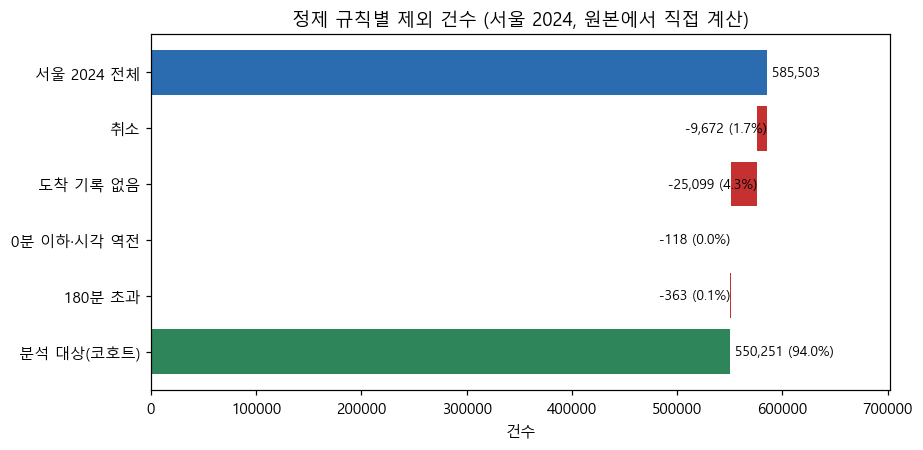

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
labels = [s[0] for s in steps]; vals = [s[1] for s in steps]
run = [vals[0]]
for v in vals[1:-1]: run.append(run[-1] + v)
colors = ["#2b6cb0"] + ["#c53030"] * 4 + ["#2f855a"]
y = np.arange(len(steps))[::-1]
ax.barh(y[0], vals[0], color=colors[0]); ax.text(vals[0], y[0], f" {vals[0]:,}", va="center", fontsize=9)
for i, v in enumerate(vals[1:-1], start=1):
    ax.barh(y[i], abs(v), left=run[i], color="#c53030"); ax.text(run[i - 1], y[i], f" -{abs(v):,} ({abs(v) / vals[0]:.1%})", va="center", ha="right", fontsize=9)
ax.barh(y[-1], vals[-1], color=colors[-1]); ax.text(vals[-1], y[-1], f" {vals[-1]:,} ({vals[-1] / vals[0]:.1%})", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlim(0, vals[0] * 1.2); ax.set_xlabel("건수")
ax.set_title("정제 규칙별 제외 건수 (서울 2024, 원본에서 직접 계산)")
fig.tight_layout(); fig.savefig(OUT / "P1_정제규칙별_제외건수.png"); plt.show()
pd.DataFrame(steps, columns=["단계", "건수"]).to_csv(TBL / "EDA_P1_정제규칙별_제외건수_2024.csv", index=False, encoding="utf-8-sig")

## P2. 결측률과 "도착 기록 없음"의 사유

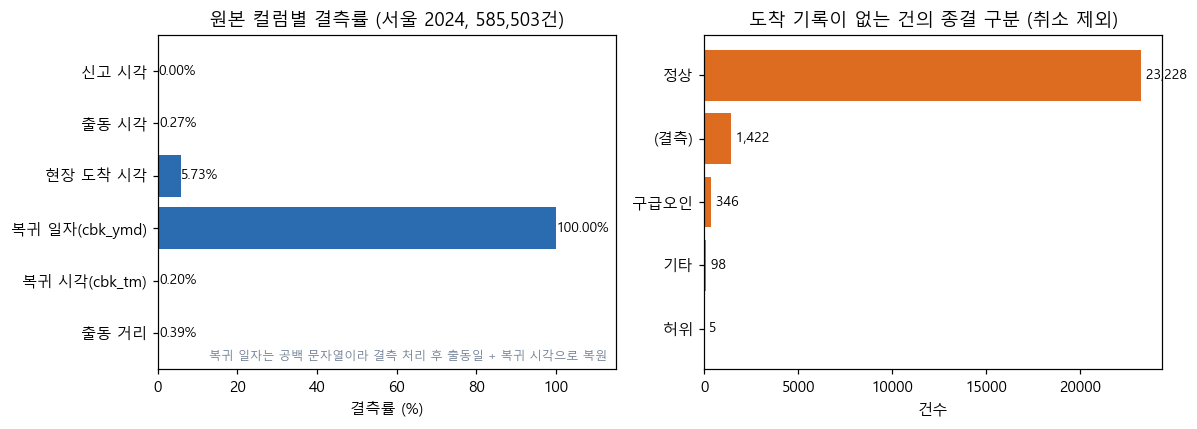

trmn_se_nm
정상      23228
(결측)     1422
구급오인      346
기타         98
허위          5
Name: count, dtype: int64

In [4]:
dist = pd.to_numeric(raw.grnds_dstnc, errors="coerce")
blank = lambda c: raw[c].isna() | raw[c].str.strip().eq("")
rate = pd.Series({"신고 시각": dclr.isna().mean(), "출동 시각": dspt.isna().mean(), "현장 도착 시각": arvl.isna().mean(), "복귀 일자(cbk_ymd)": blank("cbk_ymd").mean(), "복귀 시각(cbk_tm)": blank("cbk_tm").mean(), "출동 거리": dist.isna().mean()}) * 100
why = raw.loc[arvl.isna() & ~cancel, "trmn_se_nm"].fillna("(결측)").value_counts().head(5)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].barh(rate.index[::-1], rate.values[::-1], color="#2b6cb0")
for i, v in enumerate(rate.values[::-1]): axs[0].text(v + .1, i, f"{v:.2f}%", va="center", fontsize=9)
axs[0].text(.98, .03, "복귀 일자는 공백 문자열이라 결측 처리 후 출동일 + 복귀 시각으로 복원", transform=axs[0].transAxes, ha="right", fontsize=8, color="#718096"); axs[0].set_xlabel("결측률 (%)"); axs[0].set_title("원본 컬럼별 결측률 (서울 2024, 585,503건)"); axs[0].set_xlim(0, 115)
axs[1].barh(why.index[::-1], why.values[::-1], color="#dd6b20")
for i, v in enumerate(why.values[::-1]): axs[1].text(v, i, f" {v:,}", va="center", fontsize=9)
axs[1].set_title("도착 기록이 없는 건의 종결 구분 (취소 제외)"); axs[1].set_xlabel("건수")
fig.tight_layout(); fig.savefig(OUT / "P2_결측률_도착기록없음_사유.png"); plt.show()
rate.round(3).to_frame("결측률(%)").to_csv(TBL / "EDA_P2_결측률_2024.csv", encoding="utf-8-sig")
why.to_frame("건수").to_csv(TBL / "EDA_P2_도착없음_종결구분_2024.csv", encoding="utf-8-sig")
why

## P3. 출동 거리 분포와 이상치 (행 유지, 값만 결측 처리하는 근거)

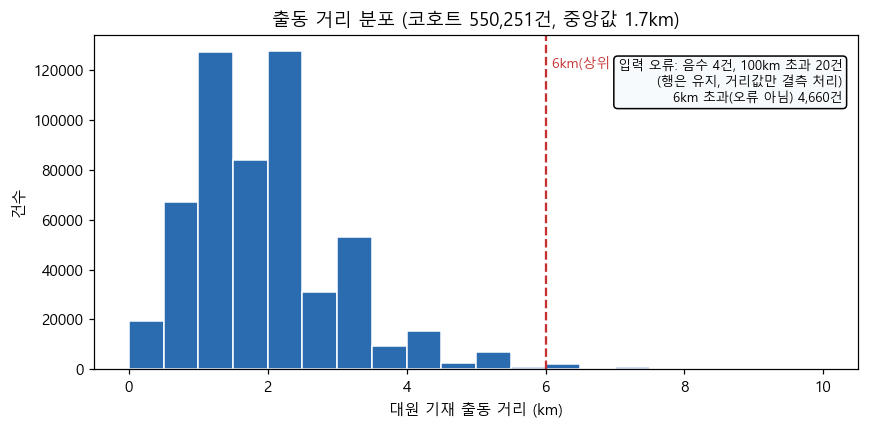

In [5]:
v = dist[kept]
n_neg = int((dist < 0).sum()); n_big = int((dist > 100).sum()); n_6 = int(((dist > 6) & (dist <= 100)).sum())
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(v[(v >= 0) & (v <= 10)], bins=np.arange(0, 10.5, .5), color="#2b6cb0", edgecolor="white")
ax.axvline(6, color="#c53030", ls="--"); ax.text(6.1, ax.get_ylim()[1] * .9, "6km(상위 1%)", color="#c53030", fontsize=9)
ax.set_xlabel("대원 기재 출동 거리 (km)"); ax.set_ylabel("건수")
ax.set_title(f"출동 거리 분포 (코호트 {int(kept.sum()):,}건, 중앙값 {v.median():.1f}km)")
ax.text(.98, .8, f"입력 오류: 음수 {n_neg}건, 100km 초과 {n_big}건{chr(10)}(행은 유지, 거리값만 결측 처리){chr(10)}6km 초과(오류 아님) {n_6:,}건", transform=ax.transAxes, ha="right", fontsize=8.5, bbox=dict(boxstyle="round", fc="#f7fafc"))
fig.tight_layout(); fig.savefig(OUT / "P3_출동거리_분포와_이상치.png"); plt.show()
pd.DataFrame({"항목": ["음수", "100km 초과", "6km 초과(100km 이하)", "중앙값(코호트)"], "값": [n_neg, n_big, n_6, v.median()]}).to_csv(TBL / "EDA_P3_거리이상치_2024.csv", index=False, encoding="utf-8-sig")

## 이후는 안전센터 코호트(2019~2024)로 분석

In [6]:
SPL = Path("data/splits/train2019-2022_calib1-12")
allv = pd.concat([pd.read_parquet(SPL / f"{s}.parquet") for s in ("train", "valid", "calib")], ignore_index=True)
allv["band"] = pd.cut(allv.hour, [-1, 5, 9, 16, 20, 23], labels=BANDS)
allv["dbin"] = pd.cut(allv.dist_km, [-0.01, 1, 2, 3, 4, 6, 1000], labels=DLAB)
c24 = allv[allv.year == 2024].copy()
c24["관외"] = c24.out_of_jur.map({0.0: "관내", 1.0: "관외"})
print(len(allv), len(c24))

2226310 528744


## Q1. 거리를 통제해도 시간대·관외출동 차이가 남는가

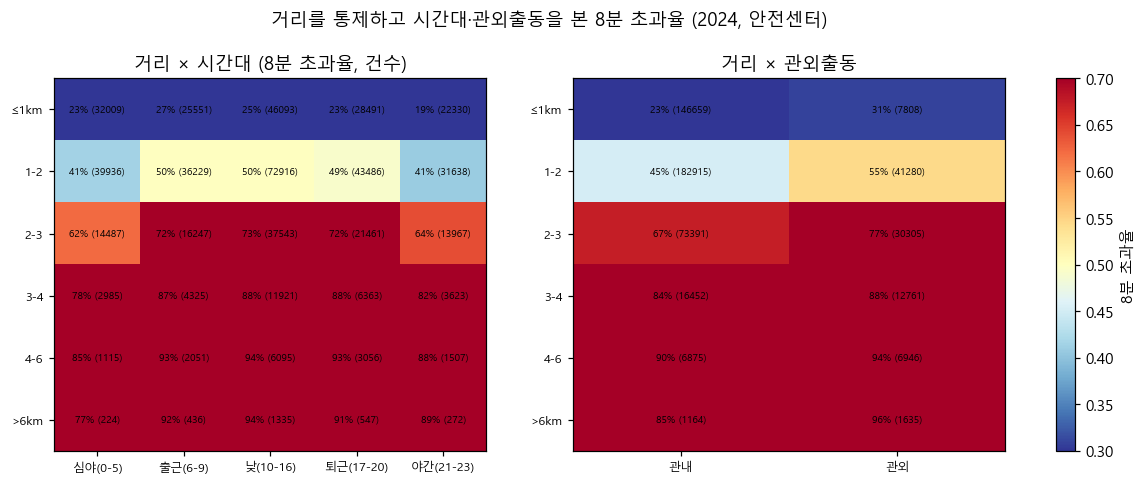

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
t1 = c24.pivot_table(index="dbin", columns="band", values="y_late", aggfunc="mean"); n1 = c24.pivot_table(index="dbin", columns="band", values="y_late", aggfunc="size")
heat(axs[0], t1, n1, "거리 × 시간대 (8분 초과율, 건수)")
t2 = c24.pivot_table(index="dbin", columns="관외", values="y_late", aggfunc="mean"); n2 = c24.pivot_table(index="dbin", columns="관외", values="y_late", aggfunc="size")
im = heat(axs[1], t2, n2, "거리 × 관외출동")
fig.colorbar(im, ax=axs, fraction=.02, label="8분 초과율"); fig.suptitle("거리를 통제하고 시간대·관외출동을 본 8분 초과율 (2024, 안전센터)", y=1.02)
fig.savefig(OUT / "Q1_거리x시간대_거리x관외.png", bbox_inches="tight"); plt.show()
t1.round(3).to_csv(TBL / "EDA_Q1_거리x시간대.csv", encoding="utf-8-sig"); t2.round(3).to_csv(TBL / "EDA_Q1_거리x관외.csv", encoding="utf-8-sig")

## Q2. 관외출동은 어느 구에서 많고, 같은 구 안에서 지연은 얼마나 다른가

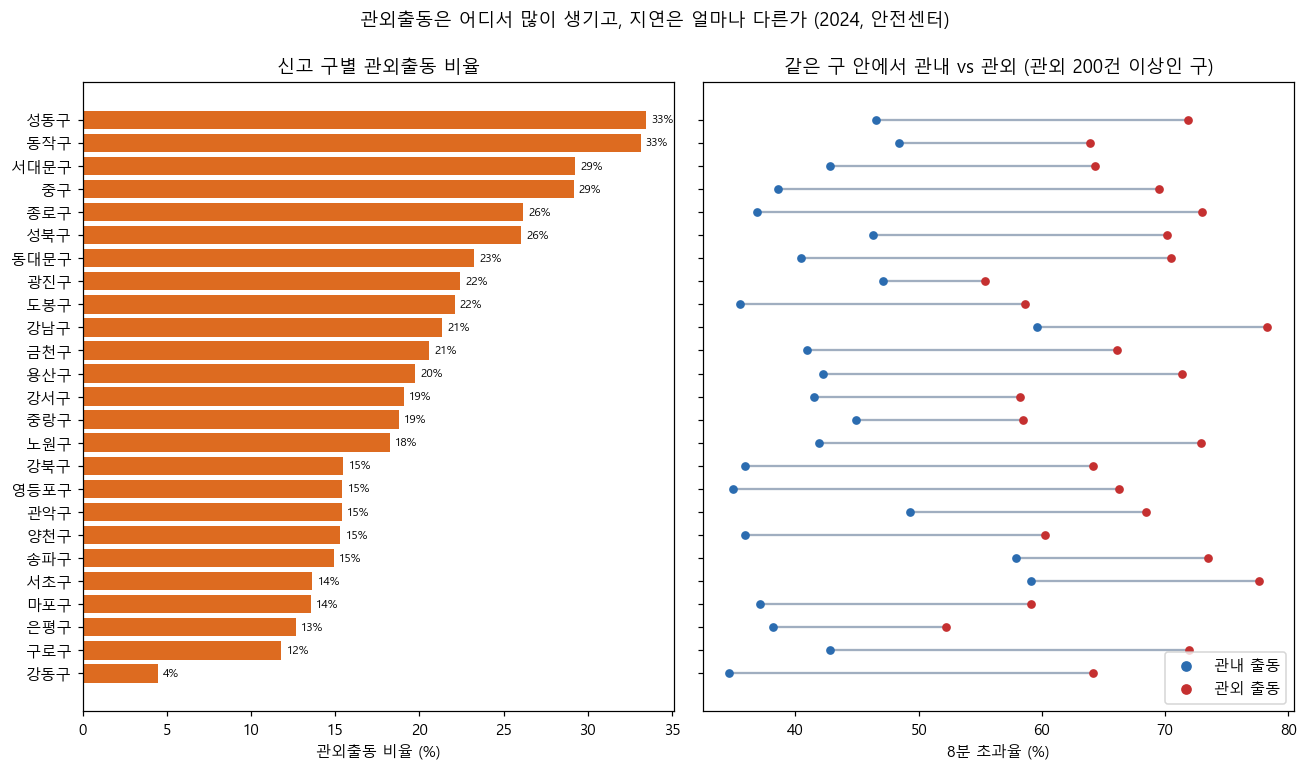

In [8]:
d = c24.dropna(subset=["out_of_jur"])
g = d.groupby("sgg").agg(n=("y_late", "size"), 관외비율=("out_of_jur", "mean"))
g["관내초과율"] = d[d.out_of_jur == 0].groupby("sgg").y_late.mean(); g["관외초과율"] = d[d.out_of_jur == 1].groupby("sgg").y_late.mean()
g["관외건수"] = d[d.out_of_jur == 1].groupby("sgg").size(); g = g.sort_values("관외비율")
fig, axs = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
axs[0].barh(g.index, g["관외비율"] * 100, color="#dd6b20")
for i, v in enumerate(g["관외비율"] * 100): axs[0].text(v + .3, i, f"{v:.0f}%", va="center", fontsize=7.5)
axs[0].set_xlabel("관외출동 비율 (%)"); axs[0].set_title("신고 구별 관외출동 비율")
big = g[g["관외건수"] >= 200]
for i, (idx, r) in enumerate(g.iterrows()):
    if idx in big.index:
        axs[1].plot([r["관내초과율"] * 100, r["관외초과율"] * 100], [i, i], color="#a0aec0", zorder=1)
        axs[1].scatter(r["관내초과율"] * 100, i, color="#2b6cb0", zorder=2, s=22); axs[1].scatter(r["관외초과율"] * 100, i, color="#c53030", zorder=2, s=22)
axs[1].scatter([], [], color="#2b6cb0", label="관내 출동"); axs[1].scatter([], [], color="#c53030", label="관외 출동"); axs[1].legend(loc="lower right")
axs[1].set_xlabel("8분 초과율 (%)"); axs[1].set_title("같은 구 안에서 관내 vs 관외 (관외 200건 이상인 구)")
fig.suptitle("관외출동은 어디서 많이 생기고, 지연은 얼마나 다른가 (2024, 안전센터)", y=.995); fig.tight_layout()
fig.savefig(OUT / "Q2_구별_관외출동.png", bbox_inches="tight"); plt.show()
g.round(3).to_csv(TBL / "EDA_Q2_구별_관외출동.csv", encoding="utf-8-sig")

## Q3. 거리를 통제해도 강수와 지연이 연관되는가 (3시간 누적 강수)

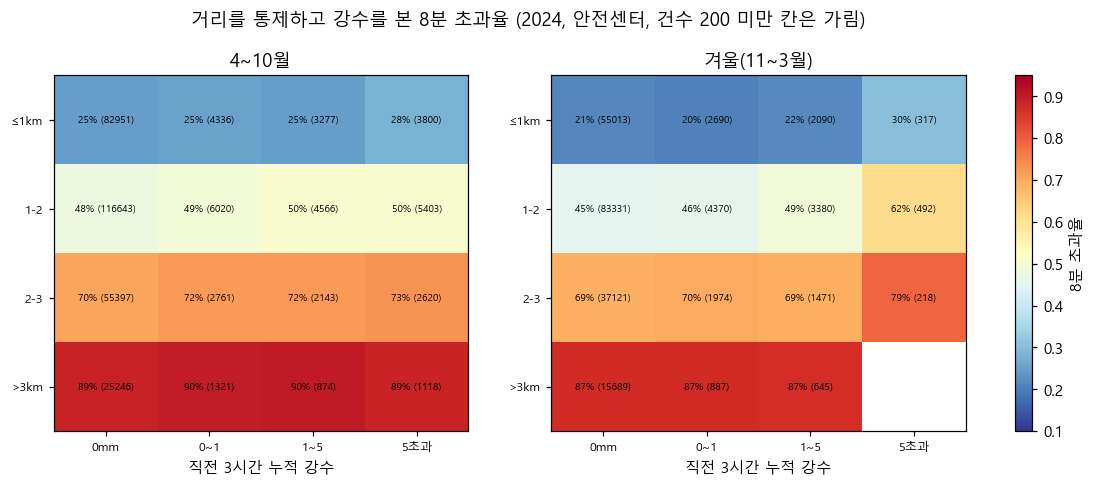

,계절,거리,강수0_초과율,강수0_건수,5mm초과_초과율,5mm초과_건수,차이(%p)
0,4~10월,≤1km,0.247,82951,0.279,3800,3.207
1,4~10월,1-2,0.477,116643,0.504,5403,2.663
2,4~10월,2-3,0.704,55397,0.729,2620,2.509
3,4~10월,>3km,0.888,25246,0.886,1118,-0.231
4,겨울(11~3월),≤1km,0.215,55013,0.303,317,8.800
5,겨울(11~3월),1-2,0.454,83331,0.618,492,16.403
6,겨울(11~3월),2-3,0.690,37121,0.789,218,9.927
7,겨울(11~3월),>3km,0.871,15689,0.867,75,-0.458


In [9]:
cfg = load_config(); w = pd.read_parquet(cfg["out"])
b = pd.read_parquet("work/base_v1/year=2024", columns=["dclr_str", "cntr_nm", "dist_raw", "resp_min"])
b = b[b.cntr_nm.str.contains("안전센터", na=False)].copy()
b["dclr"] = pd.to_datetime(b.dclr_str); b["y"] = (b.resp_min > 8).astype(int)
b["dist"] = b.dist_raw.where((b.dist_raw >= 0) & (b.dist_raw <= 100))
m = attach_rain(b, w, "dclr", cfg)
m["rbin"] = pd.cut(m.rain_3h_mm, [-0.01, 0, 1, 5, 1000], labels=["0mm", "0~1", "1~5", "5초과"])
m["dbin"] = pd.cut(m.dist, [-0.01, 1, 2, 3, 1000], labels=["≤1km", "1-2", "2-3", ">3km"])
m["season"] = np.where(m.dclr.dt.month.isin([11, 12, 1, 2, 3]), "겨울(11~3월)", "4~10월")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, s in zip(axs, ["4~10월", "겨울(11~3월)"]):
    q = m[m.season == s]
    t = q.pivot_table(index="dbin", columns="rbin", values="y", aggfunc="mean"); n = q.pivot_table(index="dbin", columns="rbin", values="y", aggfunc="size")
    im = heat(ax, t, n, s, vmin=.1, vmax=.95)
    ax.set_xlabel("직전 3시간 누적 강수")
fig.colorbar(im, ax=axs, fraction=.02, label="8분 초과율")
fig.suptitle("거리를 통제하고 강수를 본 8분 초과율 (2024, 안전센터, 건수 200 미만 칸은 가림)", y=1.02)
fig.savefig(OUT / "Q3_거리x강수_층화.png", bbox_inches="tight"); plt.show()
rows = []
for s, q in m.groupby("season"):
    for dl, r in q.groupby("dbin"):
        a = r[r.rbin == "0mm"]; c = r[r.rbin == "5초과"]
        rows.append({"계절": s, "거리": dl, "강수0_초과율": a.y.mean(), "강수0_건수": len(a), "5mm초과_초과율": c.y.mean() if len(c) else np.nan, "5mm초과_건수": len(c)})
tab = pd.DataFrame(rows); tab["차이(%p)"] = (tab["5mm초과_초과율"] - tab["강수0_초과율"]) * 100
tab.round(3).to_csv(TBL / "EDA_Q3_거리x강수_층화.csv", index=False, encoding="utf-8-sig")
tab.round(3)

## Q4. 지연은 어느 구·언제·어느 해에 큰가

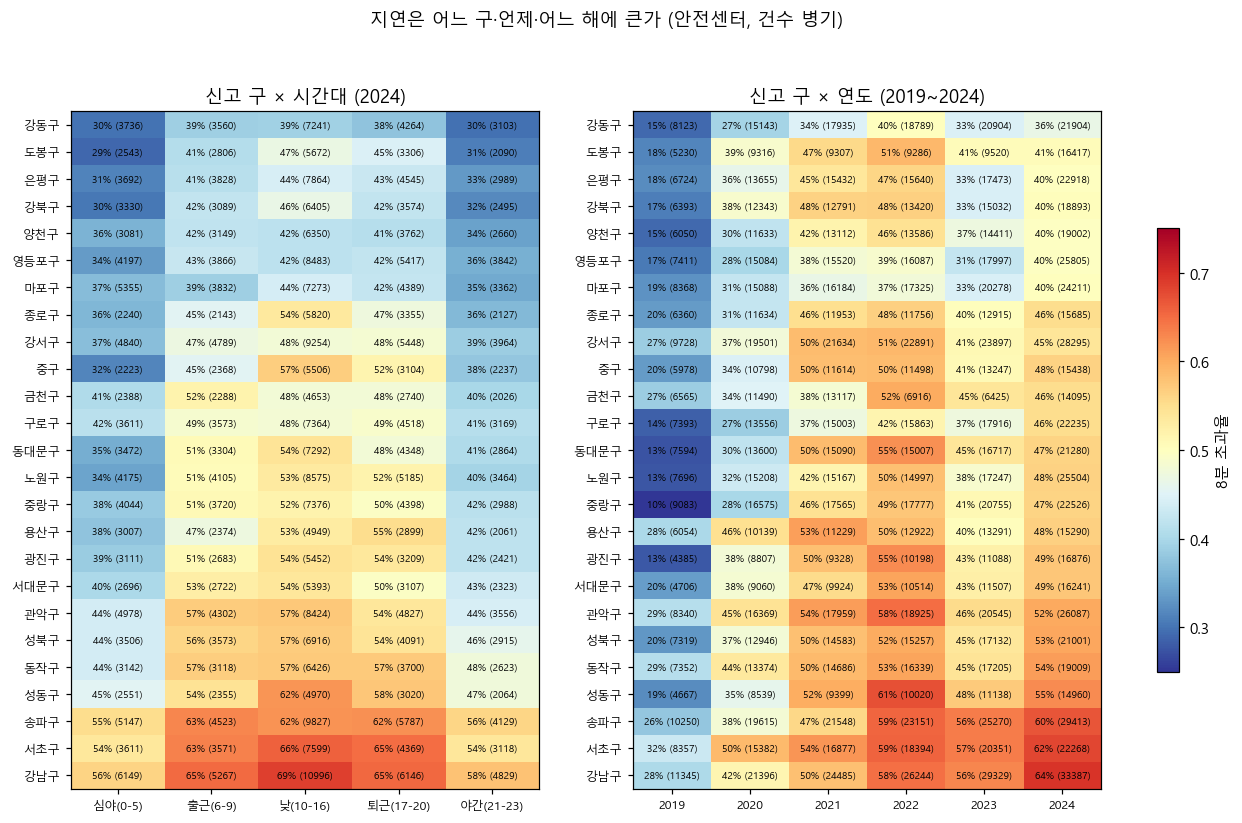

In [10]:
t3 = c24.pivot_table(index="sgg", columns="band", values="y_late", aggfunc="mean"); n3 = c24.pivot_table(index="sgg", columns="band", values="y_late", aggfunc="size")
t3 = t3.loc[t3.mean(axis=1).sort_values().index]; n3 = n3.loc[t3.index]
fig, axs = plt.subplots(1, 2, figsize=(13, 8))
im = heat(axs[0], t3, n3, "신고 구 × 시간대 (2024)", vmin=.25, vmax=.75)
t4 = allv.pivot_table(index="sgg", columns="year", values="y_late", aggfunc="mean"); n4 = allv.pivot_table(index="sgg", columns="year", values="y_late", aggfunc="size")
t4 = t4.loc[t3.index]; n4 = n4.loc[t3.index]
heat(axs[1], t4, n4, "신고 구 × 연도 (2019~2024)", vmin=.1, vmax=.7, minn=500)
fig.colorbar(im, ax=axs, fraction=.02, label="8분 초과율"); fig.suptitle("지연은 어느 구·언제·어느 해에 큰가 (안전센터, 건수 병기)", y=.995)
fig.savefig(OUT / "Q4_구x시간대_구x연도.png", bbox_inches="tight"); plt.show()
t3.round(3).to_csv(TBL / "EDA_Q4_구x시간대.csv", encoding="utf-8-sig"); t4.round(3).to_csv(TBL / "EDA_Q4_구x연도.csv", encoding="utf-8-sig")

## 튜터링용 복사

In [11]:
import shutil
SEL = {
    "1_전처리": {"P1_정제규칙별_제외건수.png": "1-1_정제규칙별_제외건수.png", "P2_결측률_도착기록없음_사유.png": "1-2_결측률_도착기록없음_사유.png", "P3_출동거리_분포와_이상치.png": "1-3_출동거리_분포_이상치.png"},
    "3_다변량": {"Q1_거리x시간대_거리x관외.png": "3-1_거리x시간대x관외.png", "Q2_구별_관외출동.png": "3-2_구별_관외출동.png", "Q3_거리x강수_층화.png": "3-3_거리x강수.png"},
}
TSEL = ["EDA_P1_정제규칙별_제외건수_2024.csv", "EDA_P2_결측률_2024.csv", "EDA_P2_도착없음_종결구분_2024.csv", "EDA_P3_거리이상치_2024.csv", "EDA_Q1_거리x시간대.csv", "EDA_Q1_거리x관외.csv", "EDA_Q2_구별_관외출동.csv", "EDA_Q3_거리x강수_층화.csv"]
for part, base in (("중간발표", Path("발표자료/중간발표")), ("튜터링", Path("기업튜터링/발표자료"))):
    for stage, files in SEL.items():
        (base / "그래프" / stage).mkdir(parents=True, exist_ok=True)
        for src, dst in files.items():
            shutil.copy(OUT / src, base / "그래프" / stage / dst)
    (base / "표").mkdir(parents=True, exist_ok=True)
    for t in TSEL:
        shutil.copy(TBL / t, base / "표" / t)
sorted(p.name for p in OUT.glob("*.png"))

['P1_정제규칙별_제외건수.png',
 'P2_결측률_도착기록없음_사유.png',
 'P3_출동거리_분포와_이상치.png',
 'Q1_거리x시간대_거리x관외.png',
 'Q2_구별_관외출동.png',
 'Q3_거리x강수_층화.png',
 'Q4_구x시간대_구x연도.png']